# Global Solution - Roubo ou furto em São Paulo (MLP)

Grupo: Emanuel Nabarrete, Luiz Eduardo e Eduardo Luiz

Objetivo: usar uma rede neural (MLP) para classificar uma ocorrência registrada na cidade de São Paulo como **roubo** ou **furto**, usando só informações do local e do horário (bairro, tipo de local, dia da semana e período do dia).

Base: dados abertos da SSP-SP (planilha de celulares subtraídos, 2024).

## 1. Imports

In [1]:
import sys
sys.path.append("src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

from data_prep import carrega_bruto, prepara

SEED = 42

## 2. Carregando os dados

A planilha da SSP fica em `data/raw/`. A função `carrega_bruto` lê só as colunas que a gente precisa.

In [2]:
bruto = carrega_bruto("data/raw")
print(bruto.shape)
bruto.head()

  lendo CelularesSubtraidos_2024.xlsx ...
  (dica: pip install python-calamine acelera muito a leitura de xlsx grandes)
(412527, 10)


,cidade,bairro,data,hora,periodo,local,rubrica,num_bo,ano_bo,delegacia
0,S.PAULO,VILA CAMPANELA,2024-01-05,NaN,A noite,Metroviário e Ferroviário Metropolitano,Furto (art. 155),AG3021,2024,DELEGACIA ELETRONICA
1,S.PAULO,VILA CAMPANELA,2024-01-03,NaN,A noite,Metroviário e Ferroviário Metropolitano,Furto (art. 155),AG3573,2024,DELEGACIA ELETRONICA
2,S.PAULO,BELEM,2023-12-30,17:00:00,NaN,Metroviário e Ferroviário Metropolitano,Furto (art. 155),AI6188,2024,12º D.P. PARI
3,S.PAULO,MOOCA,2024-01-08,NaN,A tarde,Metroviário e Ferroviário Metropolitano,Furto (art. 155),AJ6953,2024,DELEGACIA ELETRONICA
4,S.PAULO,BRÁS,2024-01-09,07:56:00,NaN,Metroviário e Ferroviário Metropolitano,Furto (art. 155),AJ7570,2024,66º D.P. JDIM ARICANDUVA


## 3. Preparação dos dados

O `prepara` (arquivo `src/data_prep.py`) faz isso:
- fica só com ocorrências cujo **local do fato** é a cidade de São Paulo (coluna `CIDADE`; a coluna `NOME_MUNICIPIO` é da delegacia, então não serve);
- cria o rótulo a partir da `RUBRICA`: roubo = 1, furto = 0 (outros crimes saem);
- tira boletins repetidos;
- cria o dia da semana e o período do dia;
- junta bairros e locais raros em "OUTROS" (ficam os 60 bairros e 15 locais mais comuns);
- sorteia 20.000 registros mantendo a proporção de roubo e furto.

A rubrica é usada **só** para criar o rótulo, ela não entra como entrada da rede (senão seria vazamento de dados, a rede já saberia a resposta).

In [3]:
df, info = prepara(bruto, seed=SEED)
df.head()

  registros_brutos: 412527
  apos_filtro_capital: 223785
  apos_rotulo: 191697
  apos_dedup: 163458
  apos_limpeza: 162563
  registros_modelo: 20000
  proporcao_roubo: 0.431


,BAIRRO,LOCAL,DIA_SEMANA,PERIODO,y
0,PINHEIROS,VIA PUBLICA,segunda-feira,A tarde,0
1,OUTROS,OUTROS,sexta-feira,A noite,0
2,ITAIM BIBI,VIA PUBLICA,quinta-feira,A tarde,0
3,REPUBLICA,OUTROS,quinta-feira,A tarde,0
4,CIDADE TIRADENTES,VIA PUBLICA,domingo,A noite,1


In [4]:
print(df.shape)
print(df["y"].value_counts())
print("Proporção de roubo:", round(df["y"].mean(), 3))

(20000, 5)
y
0    11379
1     8621
Name: count, dtype: int64
Proporção de roubo: 0.431


### Olhando os dados

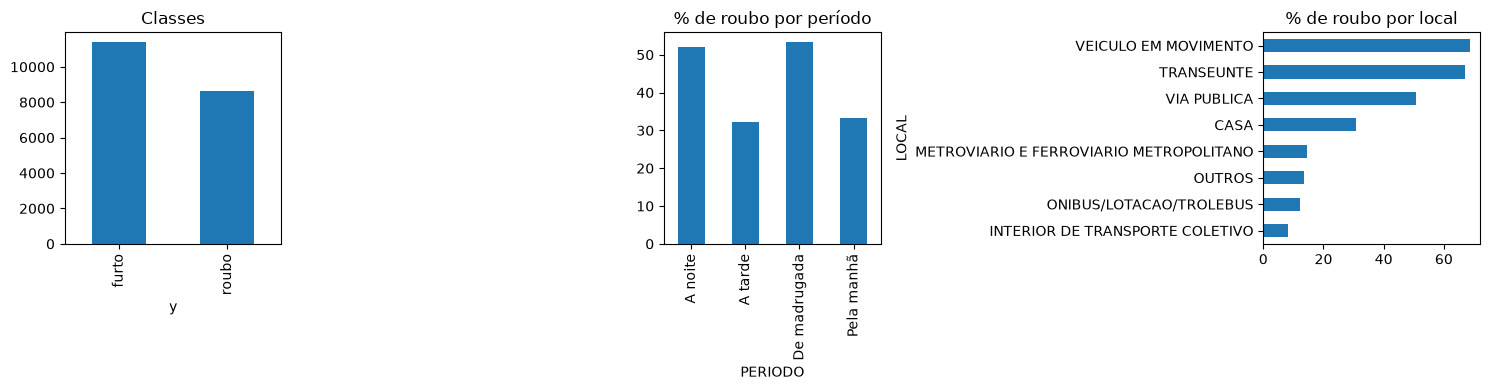

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df["y"].map({0: "furto", 1: "roubo"}).value_counts().plot(kind="bar", ax=ax[0], title="Classes")

# % de roubo por período do dia
(df.groupby("PERIODO")["y"].mean() * 100).plot(kind="bar", ax=ax[1], title="% de roubo por período")

# % de roubo por tipo de local (os 8 mais comuns)
top_locais = df["LOCAL"].value_counts().head(8).index
(df[df["LOCAL"].isin(top_locais)].groupby("LOCAL")["y"].mean() * 100).sort_values().plot(
    kind="barh", ax=ax[2], title="% de roubo por local")

plt.tight_layout()
plt.show()

Dá pra ver que o tipo de local muda bastante a proporção de roubo, então tem alguma informação nos dados. Mas só com essas 4 colunas não dá pra esperar uma acurácia muito alta.

## 4. Separando treino, validação e teste

70% treino, 15% validação e 15% teste, estratificado (mantém a proporção das classes). O teste só vai ser usado no final.

In [6]:
colunas = ["BAIRRO", "LOCAL", "DIA_SEMANA", "PERIODO"]
X = df[colunas]
y = df["y"].values

X_temp, X_teste, y_temp, y_teste = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEED)

print("treino:", len(X_treino), "| validação:", len(X_val), "| teste:", len(X_teste))

treino: 14000 | validação: 3000 | teste: 3000


## 5. Transformando as colunas em números

Todas as colunas são categorias (texto), então uso One-Hot Encoding. O encoder aprende as categorias **só com o treino** e depois só aplica na validação e no teste.

In [7]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_treino_n = encoder.fit_transform(X_treino).astype("float32")
X_val_n = encoder.transform(X_val).astype("float32")
X_teste_n = encoder.transform(X_teste).astype("float32")

n_entradas = X_treino_n.shape[1]
print("Número de entradas da rede:", n_entradas)

Número de entradas da rede: 87


### Peso das classes

Tem um pouco mais de furto do que roubo, então uso `class_weight` pra rede não ligar mais pra uma classe do que pra outra.

In [8]:
p = y_treino.mean()
pesos = {0: 0.5 / (1 - p), 1: 0.5 / p}
print(pesos)

{0: np.float64(0.8788449466415568), 1: np.float64(1.15990057995029)}


## 6. Os três modelos

Todos têm 1 neurônio de saída com sigmoide (probabilidade de ser roubo) e usam Adam e `binary_crossentropy`.

| Modelo | Camadas escondidas | Regularização |
|---|---|---|
| A | 16 | nenhuma |
| B | 64 e 32 | Dropout 0.3 |
| C | 128, 64 e 32 | Dropout 0.3 e L2 (0.0001), learning rate menor |

Uso **EarlyStopping** olhando a perda da validação (para quando não melhora por 8 épocas e volta pros melhores pesos). Isso ajuda a evitar overfitting.

In [9]:
# Modelo A - simples
keras.utils.set_random_seed(SEED)
modelo_A = keras.Sequential([
    layers.Input(shape=(n_entradas,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
modelo_A.compile(optimizer=keras.optimizers.Adam(0.001),
                 loss="binary_crossentropy", metrics=["accuracy"])

parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
hist_A = modelo_A.fit(X_treino_n, y_treino, validation_data=(X_val_n, y_val),
                      epochs=60, batch_size=64, class_weight=pesos,
                      callbacks=[parar], verbose=0)
print("Modelo A parou na época", len(hist_A.history["loss"]))

Modelo A parou na época 24


In [10]:
# Modelo B - média, com Dropout
keras.utils.set_random_seed(SEED)
modelo_B = keras.Sequential([
    layers.Input(shape=(n_entradas,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
modelo_B.compile(optimizer=keras.optimizers.Adam(0.001),
                 loss="binary_crossentropy", metrics=["accuracy"])

parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
hist_B = modelo_B.fit(X_treino_n, y_treino, validation_data=(X_val_n, y_val),
                      epochs=60, batch_size=64, class_weight=pesos,
                      callbacks=[parar], verbose=0)
print("Modelo B parou na época", len(hist_B.history["loss"]))

Modelo B parou na época 19


In [11]:
# Modelo C - mais profunda, com Dropout e L2
keras.utils.set_random_seed(SEED)
modelo_C = keras.Sequential([
    layers.Input(shape=(n_entradas,)),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
modelo_C.compile(optimizer=keras.optimizers.Adam(0.0005),
                 loss="binary_crossentropy", metrics=["accuracy"])

parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
hist_C = modelo_C.fit(X_treino_n, y_treino, validation_data=(X_val_n, y_val),
                      epochs=60, batch_size=64, class_weight=pesos,
                      callbacks=[parar], verbose=0)
print("Modelo C parou na época", len(hist_C.history["loss"]))

Modelo C parou na época 23


## 7. Comparando na validação

Calculo acurácia, precisão, recall e F1 de cada modelo na **validação** (o teste fica pra depois). Também olho a acurácia no treino pra ver se tem overfitting.

In [12]:
modelos = {"A_simples": modelo_A, "B_media": modelo_B, "C_profunda": modelo_C}
historicos = {"A_simples": hist_A, "B_media": hist_B, "C_profunda": hist_C}

linhas = []
for nome, modelo in modelos.items():
    prob_val = modelo.predict(X_val_n, verbose=0).ravel()
    pred_val = (prob_val >= 0.5).astype(int)
    prob_tr = modelo.predict(X_treino_n, verbose=0).ravel()
    pred_tr = (prob_tr >= 0.5).astype(int)

    linhas.append({
        "modelo": nome,
        "parametros": modelo.count_params(),
        "epocas": len(historicos[nome].history["loss"]),
        "val_acuracia": accuracy_score(y_val, pred_val),
        "val_precision": precision_score(y_val, pred_val),
        "val_recall": recall_score(y_val, pred_val),
        "val_f1": f1_score(y_val, pred_val),
        "treino_acuracia": accuracy_score(y_treino, pred_tr),
    })

tabela = pd.DataFrame(linhas).round(4)
tabela["gap_treino_val"] = (tabela["treino_acuracia"] - tabela["val_acuracia"]).round(4)
tabela

,modelo,parametros,epocas,val_acuracia,val_precision,val_recall,val_f1,treino_acuracia,gap_treino_val
0,A_simples,1425,24,0.685,0.6225,0.6837,0.6517,0.7011,0.0161
1,B_media,7745,19,0.683,0.6196,0.6852,0.6508,0.7087,0.0257
2,C_profunda,21633,23,0.678,0.6144,0.6790,0.6451,0.7119,0.0339


### Curvas de treino e validação (os 3 modelos)

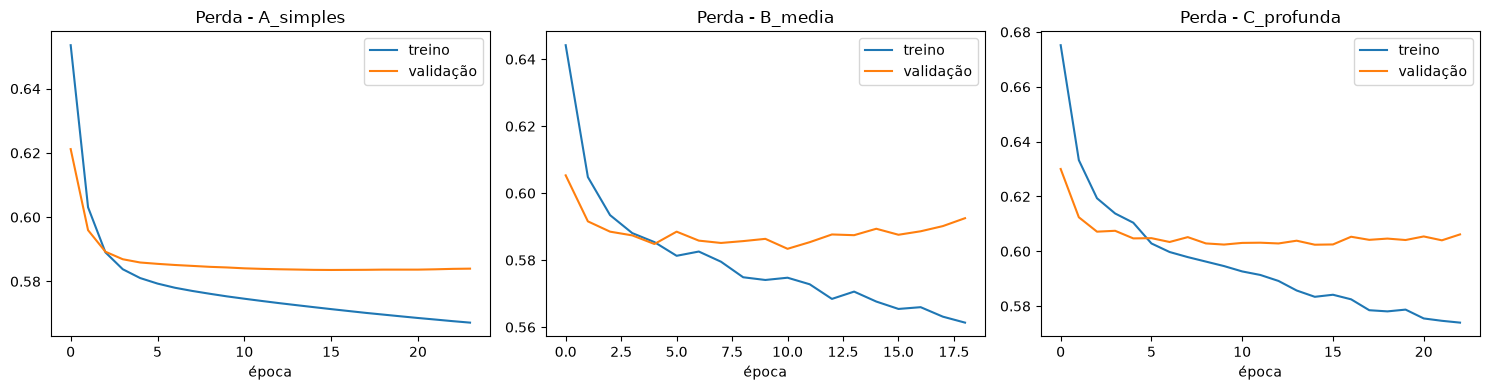

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, nome in enumerate(historicos):
    h = historicos[nome].history
    ax[i].plot(h["loss"], label="treino")
    ax[i].plot(h["val_loss"], label="validação")
    ax[i].set_title("Perda - " + nome)
    ax[i].set_xlabel("época")
    ax[i].legend()
plt.tight_layout()
plt.show()

### Análise

- Os três modelos ficaram bem parecidos na validação: acurácia entre 0,678 e 0,685 e F1 entre 0,645 e 0,652.
- O **A (simples)** teve o maior F1 na validação (0,652) e a menor diferença entre treino e validação (0,016).
- Conforme a rede fica maior, a acurácia no treino sobe (0,701 → 0,709 → 0,712) mas a de validação cai um pouco (0,685 → 0,683 → 0,678). A diferença entre as duas aumenta (0,016 → 0,026 → 0,034). Isso é um começo de **overfitting** nos modelos maiores. O Dropout, o L2 e o EarlyStopping seguraram o problema, mas não deram ganho.
- **Underfitting**: o A não parece subajustado de verdade, porque os modelos maiores não melhoraram em nada na validação. O limite aqui é a informação das colunas (só 4 atributos, e roubo e furto acontecem nos mesmos lugares e horários), não o tamanho da rede.
- Olhando as curvas, a perda de validação para de melhorar bem cedo (por volta da época 5), e depois só o treino continua melhorando.

## 8. Escolhendo o modelo

Escolho pelo maior F1 na **validação**.

In [14]:
melhor_nome = tabela.sort_values("val_f1", ascending=False).iloc[0]["modelo"]
melhor = modelos[melhor_nome]
print("Modelo escolhido:", melhor_nome)

Modelo escolhido: A_simples


## 9. Avaliação final no teste

Agora sim uso o teste, uma vez só, com o modelo escolhido.

In [15]:
prob_teste = melhor.predict(X_teste_n, verbose=0).ravel()
pred_teste = (prob_teste >= 0.5).astype(int)

print("Acurácia :", round(accuracy_score(y_teste, pred_teste), 4))
print("Precision:", round(precision_score(y_teste, pred_teste), 4))
print("Recall   :", round(recall_score(y_teste, pred_teste), 4))
print("F1       :", round(f1_score(y_teste, pred_teste), 4))

Acurácia : 0.683
Precision: 0.6213
Recall   : 0.6775
F1       : 0.6482


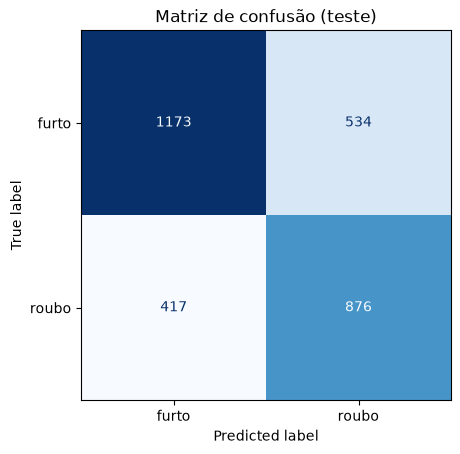

In [16]:
cm = confusion_matrix(y_teste, pred_teste)
ConfusionMatrixDisplay(cm, display_labels=["furto", "roubo"]).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão (teste)")
plt.show()

In [17]:
# Comparando com um "chute" que sempre responde furto (a classe mais comum)
print("Sempre furto:", round((y_teste == 0).mean(), 4))

Sempre furto: 0.569


### Resultado

No teste o modelo A ficou com acurácia de **0,683**, precision de 0,621, recall de 0,678 e F1 de 0,648. Isso é parecido com o que deu na validação, então o modelo não decorou os dados.

Na matriz de confusão: acertou 1173 furtos e 876 roubos, errou 534 furtos (disse que era roubo) e 417 roubos (disse que era furto).

Um chute "sempre furto" acertaria uns 57%, então o modelo ganha uns 11 pontos disso.

## 10. Conclusão

- A MLP consegue separar roubo de furto com cerca de 68% de acerto usando só bairro, local, dia da semana e período. É melhor que o chute, mas está longe de ser perfeito.
- O modelo mais simples foi o melhor na validação. Aumentar a rede só aumentou o overfitting.
- Limitações: a base só tem 4 atributos e muitos boletins não têm a hora exata (por isso usei o período do dia). Informações como valor do objeto ou se houve ameaça ajudariam muito, mas elas não estariam disponíveis na hora de usar o modelo, ou já entregariam a resposta.
- A probabilidade que o app mostra é "dado que a ocorrência já foi registrada, qual a chance de ser roubo". Não é previsão de risco de crime em um lugar.
- O modelo foi treinado com o `src/train.py` (mesma lógica deste notebook) e o app em Streamlit usa o modelo salvo por ele.

### Uso de IA

- A IA nos apoiou nas entregas com Streamlit, ferramenta nunca utilizada independente pelo grupo;
- A compreender a abrangencia da GS, nos apoiando para que nao tenha nenhuma informacao ou furo de informacoes visiveis por nos;
- Nos apoiou em algumas partes do projeto tecnico, resolvendo conosco erros de sintaxe durante todo o projeto